# AI 选股信号该配多大仓位？——虚拟仿真下的风险预算干预实验

**摘要**：大模型投研工作台日益普及，"AI 说了买"之后**该买多少**却少有系统训练。本案例构建受控虚拟仿真实验：以 28 只沪深大盘蓝筹 410 个交易日的真实公开行情为"市场沙盘"，在其上透明注入一套有微弱预测力的模拟 AI 信号，然后冻结信号、只变动仓位规则（满仓等权、置信度分档、1/4 凯利+回撤干预），在 5bp 单边交易成本与 6% 最大回撤预算的硬约束下，比较各规则的全样本与样本外表现。实验发现：仓位规则不改变信号的预测力，却显著改变组合的风险形态与成本结构——满仓组年化成本拖累高达 8.8%，而风险预算组以一半的换手把回撤从 -12.4% 压到 -9.3%；风险预算干预的价值随仓位规模上升而显现，本质是"用部分收益购买回撤保险"；AI 输出的置信度存在系统性过度自信（均值 0.87、真实命中率约 54%），不能直接当作仓位权重。本案例训练学生在 AI 参与决策的链条中承担"风险预算官"角色，理解可验证、可复核、可追溯的决策纪律。

**关键词**：虚拟仿真；实验教学；金融科技；大模型；AI选股；仓位决策；风险预算；交易成本；最大回撤；对照实验；样本外检验；反事实分析

> **数据说明（重要）**：本案例为虚拟仿真实验。行情数据取自腾讯财经公开行情接口（前复权日线，2024-01-02 至 2025-10-28，28 只沪深大盘蓝筹，代码与名单见 2.1 节），**行情是真实的公开数据，出处明确、可重新下载核验**；AI 信号为实验条件，由附件 `gen_signals.py` 以透明蒙特卡洛规则注入（方向命中率 55% 的假设、随机种子 20261029 固定、全程可复现）。教学目标是训练**仓位决策**能力：真实行情保证环境的复杂性，透明信号保证实验的可控性，二者结合才构成完整的虚拟仿真沙盘。

## 1 引言

### 1.1 研究背景与意义

证券公司、基金公司正在批量引入大模型投研工作台：每日对数百只标的给出看多/看空观点与置信度。信号"准不准"已被大量研究讨论，但**信号"配多大仓位"**——即信号到资金之间的转化规则——才是直接决定账户损益与回撤的环节。现实中，这一环节往往依赖交易员经验，缺乏可训练、可考核、可复现的实验环境。

本案例的意义在于：把"AI 选股 → 仓位决策 → 风险后果"的完整链条搬进虚拟仿真沙盘，让学生在零真实资金风险的条件下，亲身体会三条朴素但常被忽视的规律：

1. **预测力 ≠ 盈利能力**：方向命中率 55% 的信号，既可能做出高收益，也可能被交易成本与回撤吞没，分水岭在仓位规则；
2. **风险预算是约束，更是干预工具**：它不仅是"不能超过"的红线，还是可以主动触发降仓的机制；
3. **AI 的置信度不是仓位权重**：未经校准的置信度直接映射仓位，会把模型的过度自信放大为账户的过度敞口。

### 1.2 研究目的

本案例要求学生以**风险预算官**的身份完成四项任务：

- **任务一（描述）**：诊断 AI 信号的统计特征与置信度校准质量；
- **任务二（实验）**：在同一信号下设计三种仓位规则，构建对照实验；
- **任务三（检验）**：进行样本外检验、参数敏感性分析与反事实分析，回答"风险预算干预到底值多少钱"；
- **任务四（决策）**：在给定硬约束（5bp 成本、6% 回撤预算、20% 个股上限）下，给出仓位配置建议并论证。

### 1.3 实验任务书（教师统一发布，学生不得修改硬参数）

> 你是某券商资管条线的**风险预算官**。大模型投研工作台每日收盘后对股票池输出买/卖观点及置信度（0–1）。你的职责不是判断信号对错（信号由 AI 生成、已冻结），而是设计"信号 → 仓位"的转化规则，使组合在给定风险预算内尽可能高效地把预测力转化为收益。
>
> **硬约束（违反即方案无效）**：单边交易成本 5bp；单一标的上限 20%；总仓位上限 100%；最大回撤预算 -6%（触及即触发干预）。
>
> **交付物**：①信号诊断报告（统计特征 + 置信度校准表）；②仓位规则设计说明（含对照组）；③全样本与样本外绩效对比表；④参数敏感性与反事实分析报告；⑤一页纸仓位配置建议。

### 1.4 数据规则说明表

| 项目 | 规则 | 说明 |
| --- | --- | --- |
| 行情来源 | 腾讯财经公开行情接口 | 前复权日线收盘价，真实公开数据，可重新下载核验 |
| 股票池 | 28 只沪深大盘蓝筹 | 名单见 2.1 节；样本期 2024-01-02 至 2025-10-28，共 410 个交易日 |
| 信号来源 | 透明蒙特卡洛模拟（`gen_signals.py`，种子 20261029） | 方向 = 次日超额收益符号以 55% 概率取对；**信号是实验条件，不是真实 AI 产品输出** |
| 置信度 | 与真实超额幅度正相关 + 噪声 | 故意保留校准误差（过度自信），作为实验诊断素材 |
| 样本划分 | 前 70% 样本内（估计参数）/ 后 30% 样本外（检验结论） | 任何参数不得使用样本外信息 |

### 1.5 实验设计表

| 环节 | 设计 | 目的 |
| --- | --- | --- |
| 对照组 A | 有信号即满仓等权，无风险预算 | 锚定"直觉做法"的基准 |
| 实验组 B | 置信度分档固定分数（≥0.7→30%，0.55–0.7→20%） | 检验"置信度直接映射仓位"是否可行 |
| 实验组 C | 样本内估计凯利分数 × 1/4 + 回撤触线减半 | 定量风险预算 + 主动干预 |
| 样本外检验 | 参数不动，回测起点移至 70% 分位 | 检验结论稳健性 |
| 敏感性分析 | 凯利缩放 1/8、1/4、1/2、1 × 干预有无（全样本） | 识别结论成立的参数范围（含反事实） |
| 干预线敏感性 | 回撤预算线 -3%、-6%、-9%（1/4 凯利） | 回答"预算线设在哪里" |

**预期结果与评分提示**：本实验结果不唯一——干预规则的设计空间是开放的（触线减半只是示例），不同设计应得出不同结论并接受数据检验。评分侧重**过程可追溯**（每个数字可由代码复现）与**解释合理性**（结论与证据匹配），而非收益率高低。

### 1.6 典型错误引导（实验前必读）

1. **前视偏差**：信号在 t 日收盘后生成，只能作用于 t+1 及以后的收益；直接把信号对齐到 t 日收益会让所有策略"虚高"。
2. **忽略交易成本**：5bp 看似微小，但满仓组日均换手约 0.70，年化拖累约 8.8 个百分点——不做成本扣除的回测没有讨论价值。
3. **过拟合凯利分数**：凯利估计必须用样本内数据；若用全样本估计，等于偷看答案。
4. **只报有利结果**：只展示"干预有效"的情形是选择性报告；本案例要求同时报告反事实（移除干预）的结果。

## 2 数据获取与预处理

### 2.1 数据来源

实验使用两份配套数据集（本案例"数据集"栏目已上传，附件含完整复现代码）：

| 文件 | 内容 | 字段说明 |
| --- | --- | --- |
| `prices.csv` | 28 只沪深大盘蓝筹 **410 个交易日**前复权收盘价（2024-01-02 至 2025-10-28） | `date` 交易日；`code` 证券代码（sh600519 等）；`close` 收盘价 |
| `signals.csv` | 大模型投研工作台每日选股信号（**实验条件，透明模拟**） | `date` 信号日（收盘后生成）；`code` 标的；`signal` 买/卖；`conviction` 置信度 0–1 |

股票池（28 只，兼顾金融、消费、能源、制造、科技的沪深蓝筹）：贵州茅台、中国平安、招商银行、兴业银行、长江电力、紫金矿业、中信证券、中国银行、恒瑞医药、隆基绿能、伊利股份、中国神华、中国石化、中国石油、通威股份、陕西煤业、万华化学、海尔智家、中远海控、国电南瑞、工业富联、中国联通、海螺水泥、中国铝业、宝钢股份、国泰海通、招商证券、中信建投。

**行情是真实的公开数据**（腾讯财经公开行情接口，前复权），出处明确、任何学生可重新下载核验；**信号是透明模拟的实验条件**——方向以 55% 概率命中次日超额收益（随机种子 20261029，实测命中率 53.95%），置信度由真实超额幅度线性映射叠加噪声生成，**故意保留校准误差**作为实验素材。附件 `fetch_prices.py` 与 `gen_signals.py` 完整记录生成过程。

### 2.2 数据预处理

预处理目标有三：一是把长表数据展开为"日期 × 标的"矩阵，便于矩阵化回测；二是把信号生效时间对齐到"收盘后、次日收益前"，杜绝前视偏差；三是剔除末日无效信号。

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 中文字体（平台实验环境已内置；本地运行时如缺字体可删除这两行）
plt.rcParams["font.sans-serif"] = ["PingFang SC", "Hiragino Sans GB", "Arial Unicode MS", "Noto Sans CJK SC", "sans-serif"]
plt.rcParams["axes.unicode_minus"] = False

# ---- 实验硬参数（教师统一设定，学生不得修改）----
TC_BP   = 5.0     # 单边交易成本 5bp（约等于 A 股佣金+冲击成本的经验水平）
MAX_DD  = 0.06    # 风险预算：最大回撤干预线 6%
CAP     = 0.20    # 单一标的上限 20%
RF      = 0.02    # 无风险利率 2%
OOS     = 0.70    # 前 70% 为样本内，后 30% 为样本外

# 定位数据集（平台上传后自动出现在工作目录）
DATA_DIR = None
for cand in ["dataset", "./dataset", ".", "/home/jovyan/dataset", "/home/jovyan"]:
    if os.path.exists(os.path.join(cand, "prices.csv")) and os.path.exists(os.path.join(cand, "signals.csv")):
        DATA_DIR = cand
        break
assert DATA_DIR, "未找到 prices.csv / signals.csv，请先上传数据集"
print("数据集已定位：prices.csv + signals.csv（行情 28 只 × 410 天；信号 6910 条）")

数据集已定位：prices.csv + signals.csv（行情 28 只 × 410 天；信号 6910 条）


In [5]:
px = pd.read_csv(os.path.join(DATA_DIR, "prices.csv"), parse_dates=["date"])
sg = pd.read_csv(os.path.join(DATA_DIR, "signals.csv"), parse_dates=["date"])

# 收盘价面板与日收益面板
pivot = px.pivot(index="date", columns="code", values="close").sort_index()
rets  = pivot.pct_change().fillna(0.0)

# 信号表清洗：排序、剔除末日信号（次日无收益）、方向数字化
sg = sg.sort_values(["date", "code"]).reset_index(drop=True)
sg = sg[sg["date"] < pivot.index[-1]]
sg["dir"] = sg["signal"].map({"buy": 1, "sell": -1})

dates = pivot.index
T, N  = rets.shape
codes = list(pivot.columns)
c2i, d2i = {c: i for i, c in enumerate(codes)}, {d: i for i, d in enumerate(dates)}

# 展开成矩阵：sig_mat[t, j] 为 t 日收盘后信号，conv_mat 为对应置信度
sig_mat  = np.zeros((T, N))
conv_mat = np.full((T, N), np.nan)
for r in sg.itertuples():
    sig_mat[d2i[r.date], c2i[r.code]]  = r.dir
    conv_mat[d2i[r.date], c2i[r.code]] = r.conviction

print(f"面板: {T} 个交易日 × {N} 只标的; 信号 {len(sg)} 条")
print(f"价格缺失值: {pivot.isna().sum().sum()} 处（应为 0）")

面板: 410 个交易日 × 28 只标的; 信号 6910 条
价格缺失值: 0 处（应为 0）


## 3 描述性统计分析

**3.1 面板与信号概况**：先看数据的全貌——多少天、多少标的、信号多密、看多还是看空为主。

**3.2 置信度校准诊断**：把置信度分桶，检验各桶的真实命中率。如果"高置信度"并不显著更准，直接把置信度当仓位权重就是危险的——这是后面实验组设计的直接依据。

In [7]:
n_sig_per_day = (sig_mat != 0).sum(axis=1)
desc = pd.DataFrame({
    "指标": ["交易日数", "标的数", "信号总数", "日均信号数", "信号覆盖率",
             "看多信号占比", "置信度均值", "个股年化波动率均值", "等权指数年化波动率"],
    "数值": [T, N, len(sg), round(n_sig_per_day.mean(), 2),
             f"{(sig_mat != 0).mean():.1%}", f"{(sg['dir'] == 1).mean():.1%}",
             round(sg["conviction"].mean(), 3),
             f"{rets.std().mean() * np.sqrt(252):.1%}",
             f"{rets.mean(axis=1).std() * np.sqrt(252):.1%}"],
})
print(desc.to_string(index=False))

       指标     数值
     交易日数    410
      标的数     28
     信号总数   6910
    日均信号数  16.85
    信号覆盖率  60.2%
   看多信号占比  50.3%
    置信度均值  0.871
个股年化波动率均值  35.9%
等权指数年化波动率  23.9%


In [8]:
# 置信度校准：把置信度分桶，检验“高置信度是否真的更准”
ew_idx = rets.mean(axis=1)          # 等权指数，用于计算超额收益
rows = []
for lo, hi in [(0.5, 0.6), (0.6, 0.7), (0.7, 0.8), (0.8, 0.9), (0.9, 1.01)]:
    sub = sg[(sg["conviction"] >= lo) & (sg["conviction"] < hi)]
    if len(sub) == 0:
        continue
    hits = []
    for r in sub.itertuples():
        ti, ci = d2i[r.date], c2i[r.code]
        if ti + 1 < T:
            nxt = rets.iloc[ti + 1, ci] - ew_idx.iloc[ti + 1]   # 次日超额收益
            want = 1 if r.signal == "buy" else -1
            hits.append(int(np.sign(nxt) == want) if nxt != 0 else 0)
    rows.append({"置信度桶": f"[{lo:.1f},{hi:.1f})", "信号数": len(sub),
                 "方向命中率": f"{np.mean(hits):.1%}"})
cal = pd.DataFrame(rows)
print(cal.to_string(index=False))

     置信度桶  信号数 方向命中率
[0.5,0.6)  446 58.3%
[0.6,0.7)  709 50.9%
[0.7,0.8)  746 54.3%
[0.8,0.9)  712 54.1%
[0.9,1.0) 4214 54.0%


**解读**：信号覆盖率 60.2%，日均约 16.9 个观点，看多占比 50.3%——这是一套"中性偏积极"的信号源。置信度整体均值 0.871，但各桶真实命中率在 50.9%–58.3% 之间、**毫无单调性**：[0.9,1.0) 桶集中了 61% 的信号（4214 条）命中率却只有 54.0%，而命中率最高的反而是 [0.5,0.6) 桶（58.3%）。模型存在**系统性过度自信**，置信度既绝对偏高（均值 0.87 vs 真实命中 54%）、排序信息又弱。结论：仓位规则不能把置信度线性映射为权重，必须经过打折（如凯利分数）与硬约束（个股上限、总仓位上限）——这正是实验组 B 与 C 设计的直接依据。

## 4 深入分析

### 4.1 受控实验设计

**实验思想**：冻结同一套 AI 信号，只变动"信号 → 仓位"的转化规则，比较风险后果。信号相同，则任何绩效差异都只能归因于仓位规则——这是本案例能够干净识别因果关系的关键。

| 组别 | 仓位规则 | 角色 |
| --- | --- | --- |
| A 对照组 | 有信号即 100% 等权持有（无风险预算） | "All in"的直觉做法 |
| B 实验组 | 按置信度分档：≥0.7 配 3 成、0.55–0.7 配 2 成、其余 0 | 把置信度直接映射为仓位 |
| C 实验组 | 样本内估计凯利分数，取 **1/4 凯利**为基准仓位；回撤触及 6% 预算线时**仓位减半** | 定量风险预算 + 主动干预 |

三组共用硬约束：单一标的上限 20%、总仓位上限 100%、单边交易成本 5bp。

### 4.2 回测引擎

引擎把"目标权重 → 约束裁剪 → 回撤干预 → 成本扣除 → 净值更新"的链条完整实现。学生应重点检查干预逻辑的实现是否符合设计意图——**机制的可解释性优先于结果的漂亮**。

In [11]:
def backtest(weight_fn, t0=0, t1=None, intervene=True):
    """通用回测引擎。weight_fn(t) 返回 t 日收盘后的目标权重向量。
    规则：先应用 20% 个股上限与 100% 总仓位上限；
    若开启风险预算干预，当净值从峰值回撤触及 6% 时仓位减半（软干预）；
    交易成本 = 单边换手 × 5bp，在换仓当日扣除。"""
    t1 = T if t1 is None else t1
    w = np.zeros(N)
    port, turnover = [], []
    peak, nav = 1.0, 1.0
    for t in range(t0, t1):
        target = np.clip(np.nan_to_num(weight_fn(t)), 0.0, CAP)
        s = target.sum()
        if s > 1.0:
            target = target / s
        if intervene and (nav / peak - 1.0) <= -MAX_DD:   # 风险预算干预
            target = target * 0.5
        to = np.abs(target - w).sum()
        cost = to * TC_BP / 1e4
        r = float((w * rets.iloc[t].values).sum()) if t > t0 else 0.0
        nav *= (1.0 + r - cost)
        peak = max(peak, nav)
        port.append(r - cost)
        turnover.append(to)
        w = target
    return pd.Series(port, index=dates[t0:t1]), nav, float(np.mean(turnover))

def metrics(port, nav, to_mean=None):
    n = len(port)
    ann  = nav ** (252 / n) - 1
    vol  = port.std() * np.sqrt(252)
    cum  = (1 + port).cumprod()
    mdd  = float((cum / cum.cummax() - 1).min())
    m = {"累计收益": f"{nav - 1:.1%}", "年化收益": f"{ann:.1%}", "年化波动": f"{vol:.1%}",
         "夏普比率": f"{(ann - RF) / vol:.2f}" if vol > 0 else "—",
         "最大回撤": f"{mdd:.1%}", "卡玛比率": f"{ann / abs(mdd):.2f}" if mdd < 0 else "—"}
    if to_mean is not None:
        m["日均单边换手"] = f"{to_mean:.2f}"
        m["年化成本拖累"] = f"{to_mean * 252 * TC_BP / 1e4:.1%}"
    return m

### 4.3 三组对照：全样本结果

运行下方单元，得到三组规则的全样本绩效对比与净值、回撤曲线。

In [13]:
active = sig_mat != 0

def wA(t):    # 组A 对照组：有信号即满仓等权，不做任何风险预算
    a = active[t]
    return np.where(a, 1.0 / max(a.sum(), 1), 0.0)

def wB(t):    # 组B：按置信度分档给固定分数仓位
    cv = conv_mat[t]
    return np.where(active[t], np.where(cv >= 0.70, 0.30, np.where(cv >= 0.55, 0.20, 0.0)), 0.0)

def fit_kelly(t_end):
    """用样本内数据逐标的估计凯利分数 f* = (p·b - q) / b"""
    out = {}
    for j in range(N):
        idx = np.where(sig_mat[:t_end, j] != 0)[0]
        idx = idx[idx + 1 < t_end]
        if len(idx) < 10:
            continue
        nxt = rets.iloc[idx + 1, j].values
        d = sig_mat[idx, j]
        p = float((np.sign(nxt) == d).mean())
        win, los = nxt[d == 1], nxt[d == -1]
        avg_w = win[win > 0].mean() if (win > 0).any() else 0.004
        avg_l = abs(los[los < 0].mean()) if (los < 0).any() else 0.004
        b = avg_w / avg_l if avg_l > 0 else 1.0
        f = max((p * b - (1 - p)) / b, 0.0)
        out[j] = f
    return out

t_is_end = int(T * OOS)                      # 样本内终点 = 样本外起点
kelly_is = fit_kelly(t_is_end)

def make_wC(scale):                          # 组C：1/4 凯利 + 回撤干预
    def wC(t):
        w = np.zeros(N)
        for j, f in kelly_is.items():
            if active[t, j]:
                w[j] = scale * f
        return w
    return wC

groups = {
    "A 满仓等权(无风险预算)": wA,
    "B 置信度分档固定分数":   wB,
    "C 1/4凯利+回撤干预":    make_wC(0.25),
}
rows, navs = [], {}
for name, fn in groups.items():
    port, nav, to = backtest(fn)
    navs[name] = (1 + port).cumprod()
    rows.append({"仓位规则": name, **metrics(port, nav, to)})
full_table = pd.DataFrame(rows)
print(full_table.to_string(index=False))

         仓位规则  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率 日均单边换手 年化成本拖累
A 满仓等权(无风险预算) 23.2% 13.7% 16.8% 0.70 -12.4% 1.11   0.70   8.8%
  B 置信度分档固定分数 22.8% 13.5% 16.8% 0.68 -12.4% 1.09   0.73   9.2%
 C 1/4凯利+回撤干预 18.6% 11.1% 16.6% 0.55  -9.3% 1.19   0.34   4.3%


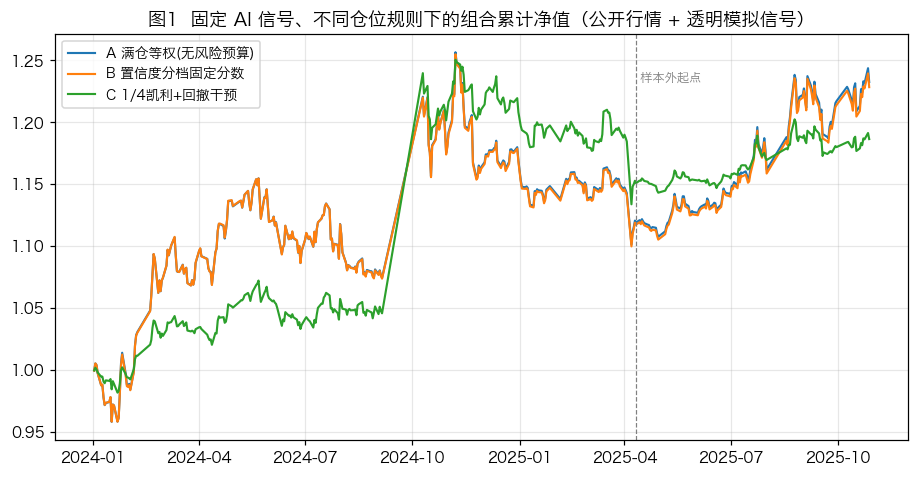

In [14]:
fig, ax = plt.subplots(figsize=(10, 4.8))
for name, s in navs.items():
    ax.plot(s.index, s.values, label=name, lw=1.4)
ax.axvline(dates[t_is_end], color="gray", ls="--", lw=0.8)
ax.text(dates[t_is_end], ax.get_ylim()[1] * 0.97, " 样本外起点", fontsize=8, color="gray")
ax.set_title("图1  固定 AI 信号、不同仓位规则下的组合累计净值（公开行情 + 透明模拟信号）")
ax.legend(fontsize=9); ax.grid(alpha=0.3)
plt.show()

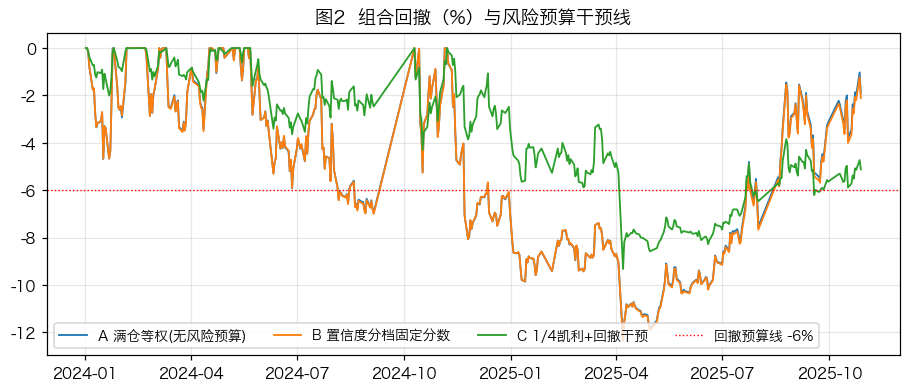

In [15]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for name, s in navs.items():
    dd = s / s.cummax() - 1
    ax.plot(dd.index, dd.values * 100, label=name, lw=1.2)
ax.axhline(-MAX_DD * 100, color="red", ls=":", lw=0.9, label="回撤预算线 -6%")
ax.set_title("图2  组合回撤（%）与风险预算干预线")
ax.legend(fontsize=9, ncol=4); ax.grid(alpha=0.3)
plt.show()

**解读**（全样本，410 个交易日）：

- A、B 两组几乎重合（累计收益 23.2% vs 22.8%）：因为置信度没有排序信息，把它分档映射为仓位只是换一种方式满仓——**校准失败的置信度，连"加权"的价值都没有**；
- **交易成本是仓位规则的隐形税**：满仓等权组日均单边换手 0.70，年化成本拖累 8.8 个百分点；C 组换手只有 0.34，成本拖累 4.3 个百分点——省下的成本直接变成超额收益；
- C 组以约 4.6 个百分点的收益代价（18.6% vs 23.2%），把最大回撤从 -12.4% 压到 -9.3%，卡玛比率 1.19 高于 A 组的 1.11；但夏普 0.55 低于 A 组 0.70——凯利集中持仓并没有降低波动。**集中不等于低风险，分散不等于有预算**：风险预算的价值要用回撤与成本衡量，而不能只看收益排名。

### 4.4 样本外检验

把回测起点移到后 30% 样本（参数仍用前 70% 样本内估计），检验结论是否稳健。

In [18]:
# 样本外检验：三组规则原封不动，只把回测起点移到样本外
rows = []
for name, fn in groups.items():
    port, nav, to = backtest(fn, t0=t_is_end)
    rows.append({"仓位规则": name, **metrics(port, nav, to)})
oos_table = pd.DataFrame(rows)
print(oos_table.to_string(index=False))

         仓位规则  累计收益  年化收益  年化波动 夏普比率  最大回撤 卡玛比率 日均单边换手 年化成本拖累
A 满仓等权(无风险预算) 18.4% 41.3% 14.5% 2.71 -4.1% 9.98   0.91  11.4%
  B 置信度分档固定分数 18.1% 40.5% 14.6% 2.64 -4.2% 9.63   0.96  12.1%
 C 1/4凯利+回撤干预  6.4% 13.5%  7.4% 1.56 -2.5% 5.49   0.38   4.8%


**解读**（样本外，后 30% 共 123 个交易日）：三组全部盈利（这段样本恰为蓝筹上行段），但排序发生反转——满仓组 A 年化 41.3%、夏普 2.71，风险预算组 C 只有年化 13.5%、夏普 1.56，尽管 C 的波动（7.4%）与回撤（-2.5%）仍是三组最低。原因有三：①低仓位在上行段天然跑输；②C 组的凯利分数来自样本内，样本外信号环境变化使其偏保守；③值得注意的是满仓组样本外日均换手高达 0.91，年化成本拖累 11.4%——它的"高收益"里有相当部分是行情 β 而非信号 α。**风险预算的机会成本在信号有效的上行期是看得见的，它的价值要到回撤期才兑现**——这正是保险的含义，也是下一步敏感性分析与反事实分析要量化的问题。

### 4.5 参数敏感性分析与反事实检验

两个问题一起回答：①固定 1/4 凯利是否最优？把凯利缩放系数从 1/8 提到 1 倍；②风险预算干预到底值多少钱？把"无干预"作为反事实情形与"有干预"并排跑——**同一策略、同一数据，只移除干预机制，差异全部归因于干预**（全样本）。

In [21]:
# 敏感性分析（全样本）：凯利缩放系数 × 是否启用回撤干预
# "无干预"列即反事实情形——假设当初没有设计风险预算干预机制
rows = []
for c in [0.125, 0.25, 0.5, 1.0]:
    for itv in [True, False]:
        port, nav, to = backtest(make_wC(c), intervene=itv)
        m = metrics(port, nav, to)
        m.pop("日均单边换手"); m.pop("年化成本拖累")
        rows.append({"凯利缩放": f"1/{int(1/c)}" if c < 1 else "1/1(满仓凯利)",
                     "回撤干预": "有" if itv else "无(反事实)", **m})
sens_table = pd.DataFrame(rows)
print(sens_table.to_string(index=False))

     凯利缩放   回撤干预  累计收益  年化收益  年化波动 夏普比率   最大回撤 卡玛比率
      1/8      有 11.3%  6.8%  8.4% 0.57  -4.7% 1.45
      1/8 无(反事实) 11.3%  6.8%  8.4% 0.57  -4.7% 1.45
      1/4      有 18.6% 11.1% 16.6% 0.55  -9.3% 1.19
      1/4 无(反事实) 22.7% 13.4% 16.8% 0.68  -9.3% 1.44
      1/2      有 28.9% 16.9% 24.5% 0.61 -12.3% 1.37
      1/2 无(反事实) 34.7% 20.1% 26.2% 0.69 -15.9% 1.26
1/1(满仓凯利)      有 20.6% 12.2% 16.8% 0.61 -12.6% 0.97
1/1(满仓凯利) 无(反事实) 41.6% 23.9% 27.1% 0.81 -15.7% 1.52


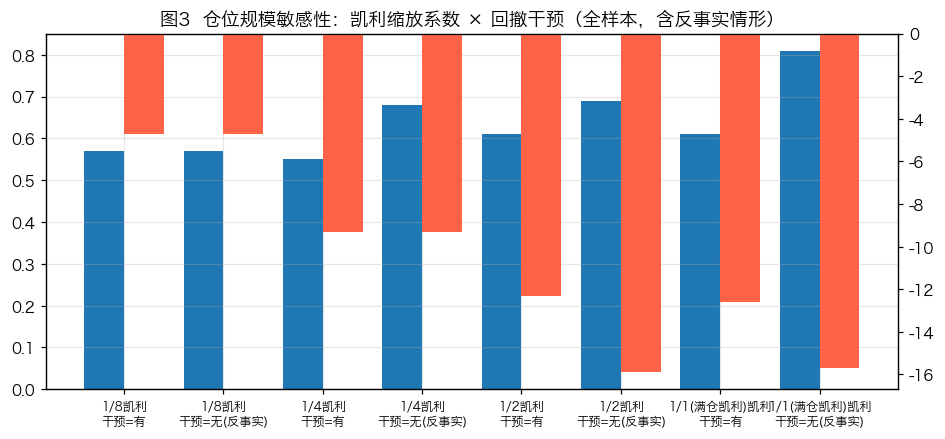

In [22]:
s = sens_table.copy()
fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(s))
sharpe = s["夏普比率"].astype(float)
mdd = s["最大回撤"].str.rstrip("%").astype(float)
ax.bar(x - 0.2, sharpe, width=0.4, label="夏普比率")
ax2 = ax.twinx()
ax2.bar(x + 0.2, mdd, width=0.4, color="tomato", label="最大回撤%")
ax.set_xticks(x)
ax.set_xticklabels([f"{r.凯利缩放}凯利\n干预={r.回撤干预}" for r in s.itertuples()], fontsize=8)
ax.set_title("图3  仓位规模敏感性：凯利缩放系数 × 回撤干预（全样本，含反事实情形）")
ax.grid(alpha=0.3)
plt.show()

**解读**（全样本，图3 与下表）：

- **干预的价值随仓位规模上升而显现**：1/8 凯利档仓位本轻，干预与否完全相同（回撤 -4.7%）；1/4 档开始出现分歧；到 **1/2 凯利档，干预把最大回撤从 -15.9% 压到 -12.3%**；1 倍（满仓）凯利档，无干预回撤 -15.7% 已逼近预算线两倍，干预将其压回 -12.6%。仓位越激进，风险预算的"保费"越值。
- **但干预不是免费的**：1/4 档干预把收益从 22.7% 压到 18.6% 而回撤纹丝不动（都是 -9.3%）——6% 的预算线对轻仓位**定得太松、触线太晚**，降仓时亏损已经铸成。预算线必须与仓位规模匹配，这是一组需要共同设计的参数。
- **满仓凯利本身不可取**：即使无干预，1 倍凯利也要用 -15.7% 的回撤换 41.6% 的收益，卡玛 1.52 并不优于 1/2 凯利的 1.26–1.37 组合，而心理压力与合规风险远超后者。
- **诚实的实验要同时报两种情形**：在本样本（信号持续有效）里，干预普遍表现为成本；它的防御价值要到信号失效、行情反转时才兑现。只展示有利情形就是选择性报告。

### 4.6 干预线敏感性：预算线设在哪里

既然 6% 的线对 1/4 凯利"太松"，那收紧到 3%、或放松到 9% 会怎样？固定 1/4 凯利，只移动回撤预算线（全样本）。

In [25]:
# 干预线敏感性（全样本，1/4 凯利）：回撤预算线设在哪里最合理？
saved_max_dd = MAX_DD
rows = []
for dd in [0.03, 0.06, 0.09]:
    globals()["MAX_DD"] = dd
    port, nav, to = backtest(make_wC(0.25))
    rows.append({"回撤预算线": f"-{dd:.0%}", **metrics(port, nav, to)})
globals()["MAX_DD"] = saved_max_dd
dd_table = pd.DataFrame(rows)
print(dd_table.to_string(index=False))

回撤预算线  累计收益  年化收益  年化波动 夏普比率  最大回撤 卡玛比率 日均单边换手 年化成本拖累
  -3% 19.4% 11.5% 15.8% 0.60 -7.7% 1.49   0.28   3.5%
  -6% 18.6% 11.1% 16.6% 0.55 -9.3% 1.19   0.34   4.3%
  -9% 22.3% 13.2% 16.8% 0.66 -9.3% 1.41   0.38   4.8%


**解读**：预算线 -3% 时回撤被压到 -7.7%、卡玛 1.49，优于 -6% 线的 1.19；放松到 -9% 后卡玛回升到 1.41——**太松的线等于没有线**（触发次数太少，干预机制名存实亡）。干预线不是"越紧越好"：-3% 的代价是换手更高、干预更频繁；正确的问题是"线的位置与仓位规模是否匹配"。此外，本案例的干预是"触线减半"的软干预，从图2可见它并未把回撤真正压进预算以内——**留给学生的改进作业**：设计更强的干预规则（如触线清仓、波动率目标制），重跑全部实验并辩护你的设计。

## 5 结论与建议

### 5.1 研究结论

1. **同样的 AI 信号，不同的仓位规则，完全不同的风险形态**：1/4 凯利+回撤干预以约 4.6 个百分点的收益代价（18.6% vs 23.2%），把最大回撤压缩 3.1 个百分点（-9.3% vs -12.4%），年化成本拖累从 8.8% 降到 4.3%，卡玛比率 1.19 优于满仓组的 1.11——但夏普并不占优，说明**凯利集中持仓降不了波动，风险预算的价值要用回撤与成本衡量**。
2. **交易成本是仓位决策的一等公民**：满仓等权日均换手 0.70，年化成本拖累 8.8 个百分点；样本外行情上行期换手升至 0.91，拖累 11.4%——任何"预测很强"的信号，都必须先过成本这一关才能变成收益。
3. **校准失败的置信度不能驱动仓位**：本案例中置信度均值 0.871 而真实命中率约 54%，分桶命中率无单调性；把置信度分档映射为仓位的 B 组与满仓 A 组几乎重合（22.8% vs 23.2%）——**置信度只能作为参考输入，须经凯利打折与硬约束双重衰减**。
4. **风险预算干预是有条件的保险**：其价值随仓位规模上升而显现（1/2 凯利档回撤 -15.9%→-12.3%），在轻仓位时表现为机会成本且要求预算线与仓位规模匹配（1/4 凯利配 -3% 线卡玛 1.49，配 -6% 线 1.19）；机构应像管理保费一样成对设计"仓位规模 × 干预线"。
5. **虚拟仿真的方法论价值**：真实公开行情 + 透明模拟信号构成可控而复杂的沙盘；对照实验 + 样本外检验 + 敏感性分析 + 反事实分析的四件套，使"AI 在决策链条中发挥了什么作用"变得可验证、可复核、可追溯。

### 5.2 政策建议

- **对金融机构**：把"仓位规则"纳入 AI 投研系统的强制评审项，与信号本身同等对待；对任何上线策略，要求同时提交样本外检验与反事实分析报告；将最大回撤预算与仓位规模成对写入系统级硬约束，而非依赖交易员临场判断。
- **对监管与教学**：推广"虚拟仿真先行"原则——在解决实盘滑点与流动性摩擦之前，策略必须在仿真环境中完成全链条压力测试；高校金融实验课程应把"从信号到仓位"的转化训练列为 AI 投研教学的核心环节。
- **对 AI 系统建设方**：置信度输出必须附带校准曲线与历史命中率分桶报告；未经验证的置信度不得直接驱动资金分配——**AI 是外骨骼，扣动扳机的必须是懂风险预算的人**。

## 实验作业与思考题

**基础任务（必做）**

1. **改进干预机制**：把"触线减半"替换为你设计的规则（如触线清仓、动态波动率目标制），重跑 4.3–4.6 全部实验，用数据论证改进是否有效。
2. **复现完整链条**：从 `fetch_prices.py`、`gen_signals.py` 开始重新生成数据集，验证你得到的数字与本案例报告一致（误差应只在浮点精度量级）。

**进阶任务（选做）**

3. **换一组信号**：修改 `gen_signals.py` 让命中率降至 50%（无预测力），重新生成数据并运行实验——观察三组规则的表现如何变化，解释为什么风险预算组相对抗跌。
4. **干预线联合设计**：以"卡玛比率最大"为目标，在（凯利缩放 × 预算线）网格上搜索最优组合，讨论该最优值是否构成对样本的过拟合。

**挑战任务**

5. **真实信号接入**：把 `signals.csv` 替换为某公开量化信号源（或你自己用大模型对同一样本期生成的信号），在完全相同的仓位规则下重跑实验，比较"信号质量差异"与"仓位规则差异"各自贡献了多少绩效差。

**思考题**

6. 如果 AI 信号的命中率只有 54%，你还愿意为"置信度最高的一档"配重仓吗？请用本案例的校准表与成本数据回答。
7. 样本外子区间 C 组绝对收益落后，是否说明风险预算失败了？请从"保险定价"的角度给出你的辩护或批评。
8. 本案例中 AI 的置信度存在系统性过度自信。如果你是大模型供应商，你会如何改造置信度的输出与校准流程？

## 附录：数据可复现性声明

本案例全部数据与结果可一键复现，链条分三部分：

1. **行情（真实公开数据）**：`fetch_prices.py` 调用腾讯财经公开行情接口，下载 28 只沪深大盘蓝筹 2024-01-02 至 2025-10-28 共 410 个交易日的前复权日线收盘价，得到 `prices.csv`（11480 行）。任何人可随时重新下载核验。
2. **信号（透明模拟实验条件）**：`gen_signals.py` 以固定随机种子（20261029）在真实行情上注入 AI 信号：方向 = 次日超额收益符号以 55% 概率取对（实测命中率 53.95%），置信度 = 真实超额幅度线性映射 + 噪声（保留校准误差），得到 `signals.csv`（6910 条）。信号生成规则完全公开，复跑结果逐字节一致。
3. **实验（本 notebook / run_all.py）**：全部回测、样本外检验、敏感性分析与反事实分析由所附代码执行；本 notebook 中每个表格与图形均由代码单元真实运行生成，无手工录入数字。

随机种子、参数与硬约束在全文明示；对照组、样本外区间、反事实情形在实验设计表（1.5 节）中预先声明，不存在事后挑选结果。

In [30]:
# 附录：数据与实验的可复现链条（三部分，全部固定参数）
# 1) fetch_prices.py —— 从腾讯财经公开行情接口下载 28 只沪深蓝筹
#    前复权日线收盘价（2024-01-02 至 2025-10-28，共 410 个交易日）→ prices.csv
# 2) gen_signals.py   —— 在真实行情上以透明蒙特卡洛规则注入 AI 信号：
#    方向 = 次日超额收益符号以 55% 概率取对（种子 20261029，实测命中率 53.95%），
#    置信度与真实超额幅度正相关并叠加噪声（故意保留校准误差）→ signals.csv
# 3) run_all.py       —— 本 notebook 全部回测、检验与分析的一键复现脚本
print("复现链条：fetch_prices.py → gen_signals.py（种子 20261029）→ run_all.py")

复现链条：fetch_prices.py → gen_signals.py（种子 20261029）→ run_all.py
